# Unidad III: Analisis Supervisado (Regresion y Clasificacion)
**Proyecto:** Clasificacion automatica y analisis morfologico de variedades de frijol  
**Estudiante:** Kevin Hernandez Trejo (23300950) | 10IDGS-G1  
**Hito de Evaluacion:** Modelos de Regresion y Clasificacion Funcionando

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

data_path = os.path.join("..", "data", "processed", "dry_beans_cleaned.csv")
df = pd.read_csv(data_path)
print(f"Dataset cargado para modelado supervisado: {df.shape[0]} registros.")

Dataset cargado para modelado supervisado: 13543 registros.


## 1. Tarea de Regresion: Prediccion de Superficie (`Area`)
**Tratamiento de Data Leakage:** Se excluye `EquivDiameter` (calculado deterministamente como $\sqrt{4A/\pi}$) y `ConvexArea` para medir el verdadero aporte de los factores de forma y ejes.

In [2]:
reg_features = [
    "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "AspectRatio", "Eccentricity", "Extent", "Solidity",
    "Roundness", "ShapeFactor3", "ShapeFactor4"
]
X_reg = df[reg_features]
y_reg = df["Area"]

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.20, random_state=42)

# Modelo Baseline: Regresion Lineal Multiple
lr_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
lr_pipe.fit(X_tr_r, y_tr_r)
y_pred_lr = lr_pipe.predict(X_te_r)

# Modelo No Lineal: Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_reg.fit(X_tr_r, y_tr_r)
y_pred_rf = rf_reg.predict(X_te_r)

print("--- DESEMPENO DE REGRESION ---")
print(f"Regresion Lineal: R2 = {r2_score(y_te_r, y_pred_lr):.4f} | MAE = {mean_absolute_error(y_te_r, y_pred_lr):.2f} px | RMSE = {np.sqrt(mean_squared_error(y_te_r, y_pred_lr)):.2f} px")
print(f"Random Forest:    R2 = {r2_score(y_te_r, y_pred_rf):.4f} | MAE = {mean_absolute_error(y_te_r, y_pred_rf):.2f} px | RMSE = {np.sqrt(mean_squared_error(y_te_r, y_pred_rf)):.2f} px")

--- DESEMPENO DE REGRESION ---
Regresion Lineal: R2 = 0.9799 | MAE = 3112.06 px | RMSE = 4237.15 px
Random Forest:    R2 = 0.9997 | MAE = 191.79 px | RMSE = 527.65 px


## 2. Tarea de Clasificacion Multiclase (7 Variedades)
Particion estratificada 80/20 para controlar el desbalance entre variedades (ej. Dermason con 3,546 vs Bombay con 522). Se prioriza la metrica **Macro F1-Score**.

In [3]:
X_clf = df.drop(columns=["Class"])
y_clf = df["Class"]

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

modelos = {
    "Regresion Logistica": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    "k-NN (k=5)": Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=120, max_depth=15, random_state=42, n_jobs=-1)
}

resultados = []
for nombre, m in modelos.items():
    m.fit(X_tr_c, y_tr_c)
    preds = m.predict(X_te_c)
    acc = accuracy_score(y_te_c, preds)
    mf1 = f1_score(y_te_c, preds, average="macro")
    resultados.append({"Modelo": nombre, "Accuracy": acc, "Macro F1": mf1})

df_res = pd.DataFrame(resultados)
print(df_res.to_string(index=False))

                  Modelo  Accuracy  Macro F1
     Regresion Logistica  0.919158  0.930237
              k-NN (k=5)  0.915467  0.927027
Random Forest Classifier  0.920266  0.931805


### 3. Matriz de Confusion - Mejor Clasificador (Random Forest)

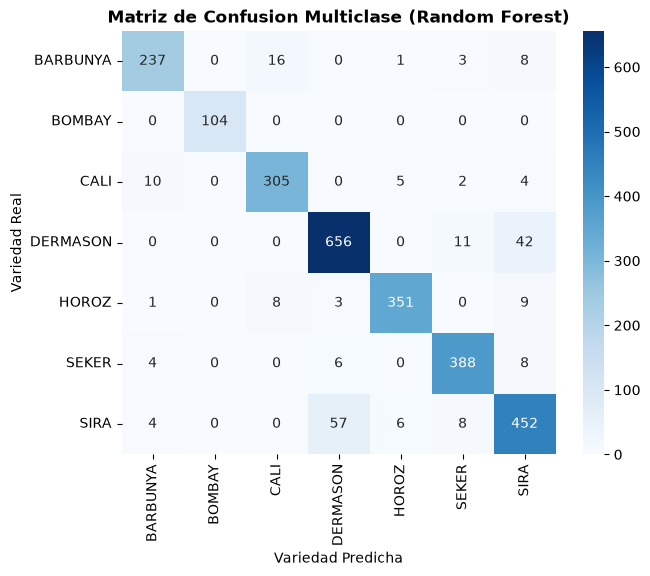

In [4]:
rf_best = modelos["Random Forest Classifier"]
preds_rf = rf_best.predict(X_te_c)
clases = sorted(df["Class"].unique())
cm = confusion_matrix(y_te_c, preds_rf, labels=clases)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.title("Matriz de Confusion Multiclase (Random Forest)", fontsize=12, fontweight="bold")
plt.xlabel("Variedad Predicha")
plt.ylabel("Variedad Real")
plt.show()